### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [1]:
import sys
sys.path.append("../src")

from types import SimpleNamespace
import os

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import properscoring as ps


from configs.load_config import load_config
from models.build import build_model

from data_processing.load import (
    load_evaluation_data,
    load_evaluation_forecast_data,
    load_scaler_params,
)

from data_processing.utils import load_checkpoint, extract_test_dates

from training.evaluate import test_QR, test_BNN, crps_from_quantiles

from training.plot import (
    plot_qr_hdi_prediction_ensemble,
    plot_bnn_gamma_combined,
    plot_qr_prediction_ensemble
)

%load_ext autoreload
%autoreload 2

### Load evaluation data


In [2]:
representative_test_set = False

In [3]:
# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_02_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-28_18-30-32_nowcast_ELSPOT_NO2"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-29_01-53-28_nowcast_ELSPOT_NO3"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_04_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-29_07-02-26_nowcast_ELSPOT_NO4"

# # Synthetic data
# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-25_10-23-37_nowcast_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/torch_model_quantile_01.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_weighted_2026-04-09_10-26-25_nowcast_gen_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/torch_model_quantile_02.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2"

# model_cfg = load_config("../configs/model/torch_model_quantile_03.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_weighted_2026-04-09_10-27-30_nowcast_gen_ELSPOT_NO3"

model_cfg = load_config("../configs/model/torch_model_quantile_04.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4"


data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [4]:
bid_zone = model_cfg.data.bid_zone
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]

# Scale nowcast and forecast with same scalers
scaler_data_nowcast = load_scaler_params(
    bid_zone=bid_zone, dataset="nowcast", dir_path="../checkpoints"
)

dataset = "forecast"  # data_cfg.dataset
if dataset == "nowcast":
    evaluation_dates = [
        "2025-09-22",
        "2025-09-23",
        "2025-09-24",
        "2025-09-25",
        "2025-09-26",
        "2025-09-29",
        "2025-09-30",
        # "2025-10-01",
        # "2025-10-02",
        # "2025-10-03",
    ]

    eval_data = load_evaluation_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_nowcast["scaler_params"],
        site_scaler_params=scaler_data_nowcast["site_scaler_params"],
        bid_zone=bid_zone,
    )

elif dataset == "forecast":
    evaluation_dates = (
        [
            "2025-09-22",
            "2025-09-23",
            "2025-09-24",
            "2025-09-25",
            "2025-09-26",
            "2025-09-29",
            "2025-09-30",
            "2025-10-01",
            "2025-10-02",
            "2025-10-03",
        ]
        if not representative_test_set
        else extract_test_dates()
    )

    eval_data = load_evaluation_forecast_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_nowcast["scaler_params"],
        site_scaler_params=scaler_data_nowcast["site_scaler_params"],
        bid_zone=bid_zone,
        ensemble_members=None,
        variance_feature=False,
    )

Loaded scaler parameters for ELSPOT NO4 and nowcast
  Saved at: 2026-04-07 15:27:48
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 10 dates in zone ELSPOT NO4...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-23 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-24 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-25 i

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (240, 13, 15, 10)
Dropped timestamps due to maintenance: 0


In [5]:
# assert np.allclose(eval_data["X_eval"], eval_data_eff["X_eval"])

In [6]:
model_name_for_title = "BNN" if model_cfg.backend == "numpyro" else "QRNN"

### Evaluate on test set


In [7]:
forecasts_ext = []
preds_list = []
for member in range(15):

    if model_cfg.backend == "numpyro":

        forecast, forecast_extended, bz_from_checkpoint, preds = test_BNN(
            file_name, eval_data, member=member
        )

    elif model_cfg.backend == "torch":

        forecast, forecast_extended, bz_from_checkpoint, preds = test_QR(
            file_name,
            eval_data,
            ensembles=False,
            from_now_to_forecast=True,
            member=member,
        )
        checkpoint = torch.load(
            os.path.join("../checkpoints", f"{file_name}.pt"),
            map_location="cpu",
            weights_only=False,
        )

    forecasts_ext.append(forecast_extended[int(bz_from_checkpoint[-1]) - 1])
    preds_list.append(preds)

    if dataset == "nowcast":
        print("We use nowcast, so only one iteration")
        break

Choose ensemble member 0
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4.pt
  Model class: WindPowerQuantile_weighted
Choose ensemble member 1
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4.pt
  Model class: WindPowerQuantile_weighted
Choose ensemble member 2
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4.pt
  Model class: WindPowerQuantile_weighted
Choose ensemble member 3
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4.pt
  Model class: WindPowerQuantile_weighted
Choose ensemble member 4
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4.pt
  Model class: WindPowerQuantile_weighted
Choose ensemble member 5
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4.pt
  Model class: WindPowerQuantile_weighted
Choose ensemble member 6
Loaded model: WindPowerQuantile_weighted_2026-04-09

In [8]:
df_out = pd.concat(forecasts_ext, axis=1, keys=range(len(forecasts_ext)))
df_out.columns = [f"{col}_{i}" for i, col in df_out.columns]
print(df_out)

median_cols = df_out.filter(regex=r"^median_").columns
hdi_lower_cols = df_out.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = df_out.filter(regex=r"^hdi_upper_").columns

df_out["mean_median"] = df_out[median_cols].mean(axis=1)
df_out["std_median"] = df_out[median_cols].std(axis=1)
df_out["mean_hdi_lower"] = df_out[hdi_lower_cols].mean(axis=1)
df_out["std_hdi_lower"] = df_out[hdi_lower_cols].std(axis=1)
df_out["mean_hdi_upper"] = df_out[hdi_upper_cols].mean(axis=1)
df_out["std_hdi_upper"] = df_out[hdi_upper_cols].std(axis=1)

                             median_0  hdi_lower_0  hdi_upper_0    median_1  \
2025-09-24 00:00:00+02:00  247.009293   123.146736   419.873413  319.407959   
2025-09-24 01:00:00+02:00  251.470871   128.382019   419.145721  305.502228   
2025-09-24 02:00:00+02:00  237.307434   119.935616   394.922119  292.508240   
2025-09-24 03:00:00+02:00  222.420105   107.637314   375.114441  284.019775   
2025-09-24 04:00:00+02:00  194.527695    88.888443   335.149384  328.250488   
...                               ...          ...          ...         ...   
2025-10-05 19:00:00+02:00  777.689209   508.921448   990.063538  756.171204   
2025-10-05 20:00:00+02:00  747.124451   485.005554   955.076538  729.051880   
2025-10-05 21:00:00+02:00  705.764160   453.063293   910.510376  711.011353   
2025-10-05 22:00:00+02:00  679.879639   434.634460   884.959717  683.121277   
2025-10-05 23:00:00+02:00  686.269592   443.046906   898.353394  678.221191   

                           hdi_lower_1  hdi_upper_1

In [9]:
# # Save predictions to CSV
# data_folder = f"../data/evaluation/eval_period"
# file_path = f"{data_folder}/forecast.csv"
# if not os.path.exists(data_folder):
#     os.makedirs(data_folder)
# forecast.to_csv(file_path)

In [10]:
# # Validate format
# df = validate_forecast(file_path)

### Metrics


In [11]:
# Metrics for member 0
bid_zone = model_cfg.data.bid_zone.replace(" ", "_")
i = int(bid_zone.split("NO")[-1]) - 1
print(i, bid_zone)

rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))

print("Test RMSE (gen prediction):", rmse)
inside = (eval_data["Y_eval_gen"] >= forecasts_ext[0]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecasts_ext[0]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_data["Y_eval_gen"] <= forecasts_ext[0]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

if model_cfg.backend == "numpyro":
    crps = ps.crps_ensemble(eval_data["Y_eval_gen"], preds, axis=0).mean()
else:
    if model_cfg.params.quantiles is None:
        if model_cfg.params.num_quantiles is not None:
            quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)
        else:
            quantiles = torch.linspace(0, 1, 51)
    else:
        quantiles = torch.tensor(checkpoint["model_cfg"].params.quantiles)
    Y_eval_gen = eval_data["Y_eval_gen"]
    if not isinstance(Y_eval_gen, torch.Tensor):
        Y_eval_gen = torch.tensor(Y_eval_gen, dtype=torch.float32)
    crps = crps_from_quantiles(
        Y_eval_gen,
        preds_list[0],
        quantiles,
    )
print("\nTest CRPS (gen prediction)", crps)

3 ELSPOT_NO4
Test RMSE (gen prediction): 125.4248424418863

Empirical coverage (0.025–0.975): 0.792
Below median (should be ~0.5): 0.338

Test CRPS (gen prediction) tensor(77.5754)


In [12]:
# Metrics across ensemble members (not just member 0)
if data_cfg.dataset == "forecast" and model_cfg.backend == "numpyro":
    stacked_preds = np.concatenate(preds_list, axis=0)
    percentiles_all = np.percentile(stacked_preds, [2.5, 97.5], axis=0)
    results = {}
    Y_test = eval_data["Y_eval_gen"]
    results["rmse_median"] = np.sqrt(
        np.mean((np.median(stacked_preds, axis=0) - Y_test) ** 2)
    )
    results["coverage_025_975"] = (
        (Y_test >= percentiles_all[0]) & (Y_test <= percentiles_all[1])
    ).mean()
    results["coverage_0_50"] = (Y_test <= np.median(stacked_preds)).mean()
    results["crps"] = ps.crps_ensemble(Y_test, stacked_preds, axis=0).mean()

    print(results)

In [13]:
# Metrics across ensemble members (not just member 0)

if data_cfg.dataset == "forecast" and model_cfg.backend == "torch":

    ensemble = torch.stack(preds_list, dim=0)  # [15, N, Q]
    ensemble_mean = torch.mean(ensemble, dim=0)  # [N, Q]

    median_idx = torch.argmin(torch.abs(quantiles - 0.5)).item()
    lower_idx = torch.argmin(torch.abs(quantiles - 0.025)).item()
    upper_idx = torch.argmin(torch.abs(quantiles - 0.975)).item()

    y_pred_median = ensemble_mean[:, median_idx]
    y_pred_lower = ensemble_mean[:, lower_idx]
    y_pred_upper = ensemble_mean[:, upper_idx]

    Y_test = eval_data["Y_eval_gen"]
    if not isinstance(Y_test, torch.Tensor):
        Y_test = torch.tensor(Y_test, dtype=ensemble_mean.dtype)

    results = {}
    results["rmse_median"] = torch.sqrt(torch.mean((y_pred_median - Y_test) ** 2))
    results["coverage_025_975"] = (
        ((Y_test >= y_pred_lower) & (Y_test <= y_pred_upper)).float().mean()
    )
    results["coverage_0_50"] = (Y_test <= y_pred_median).float().mean()

    results["crps"] = crps_from_quantiles(
        Y_test,
        ensemble_mean,
        quantiles,
    )

    print(results)

{'rmse_median': tensor(122.8016), 'coverage_025_975': tensor(0.8292), 'coverage_0_50': tensor(0.3292), 'crps': tensor(71.1144)}


### Plot prediction


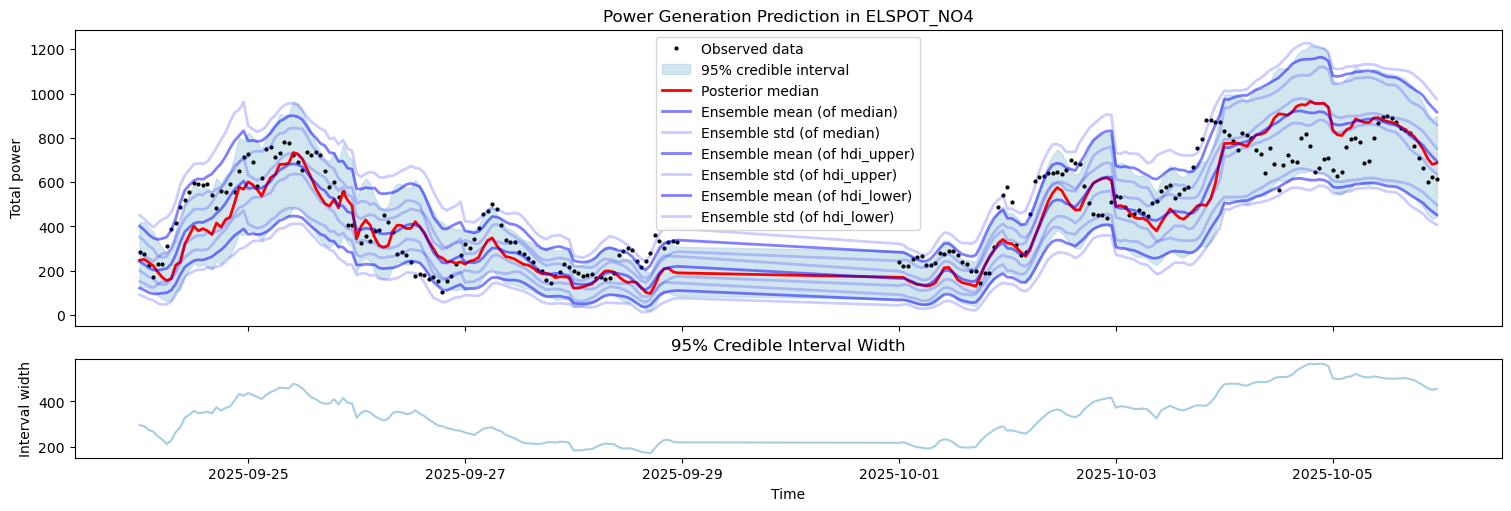

In [14]:
fig, axes = plt.subplots(
    nrows=2,
    figsize=(15, 5),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

ax = axes[0]
ax.plot(
    eval_data["index"],
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    # np.arange(len(df_out.index)),
    eval_data["index"],
    df_out["hdi_lower_0"].values,
    df_out["hdi_upper_0"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    eval_data["index"],
    df_out["median_0"].values,
    color="red",
    label="Posterior median",
    lw=2,
)

ax.set(
    ylabel="Total power",
    title=f"Power Generation Prediction in {bid_zone}",
)


# Compute interval width
width = df_out["hdi_upper_0"].values - df_out["hdi_lower_0"].values
ax2 = axes[1]
ax2.plot(eval_data["index"], width, color="#A6CEE3")
ax2.set(
    xlabel="Time",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

keys = ["median", "hdi_upper", "hdi_lower"]
colors = ["blue", "blue", "blue"]

for c, k in zip(colors, keys):
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values,
        color=c,
        lw=2,
        alpha=0.5,
        linestyle="-",
        label=f"Ensemble mean (of {k})",
    )
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values + df_out["std_" + k].values,
        color=c,
        lw=2,
        alpha=0.2,
        linestyle="-",
        # label=f"Ensemble std (of {k})",
    )
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values - df_out["std_" + k].values,
        color=c,
        lw=2,
        alpha=0.2,
        linestyle="-",
        label=f"Ensemble std (of {k})",
    )
ax.legend()

plt.show()

In [15]:
if model_cfg.backend == "numpyro":
    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], eval_data)

    plot_bnn_gamma_combined(
        checkpoint, model, eval_data, data_cfg, [0, 5000], split="eval"
    )
    # plt.show()
    title = f"../plots/ensemble_{data_cfg.dataset}_{model_cfg.data.bid_zone}_test"
    if representative_test_set:
        title + "_rep"
    # plt.savefig(f"../plots/{title}.pdf")
    plt.show()

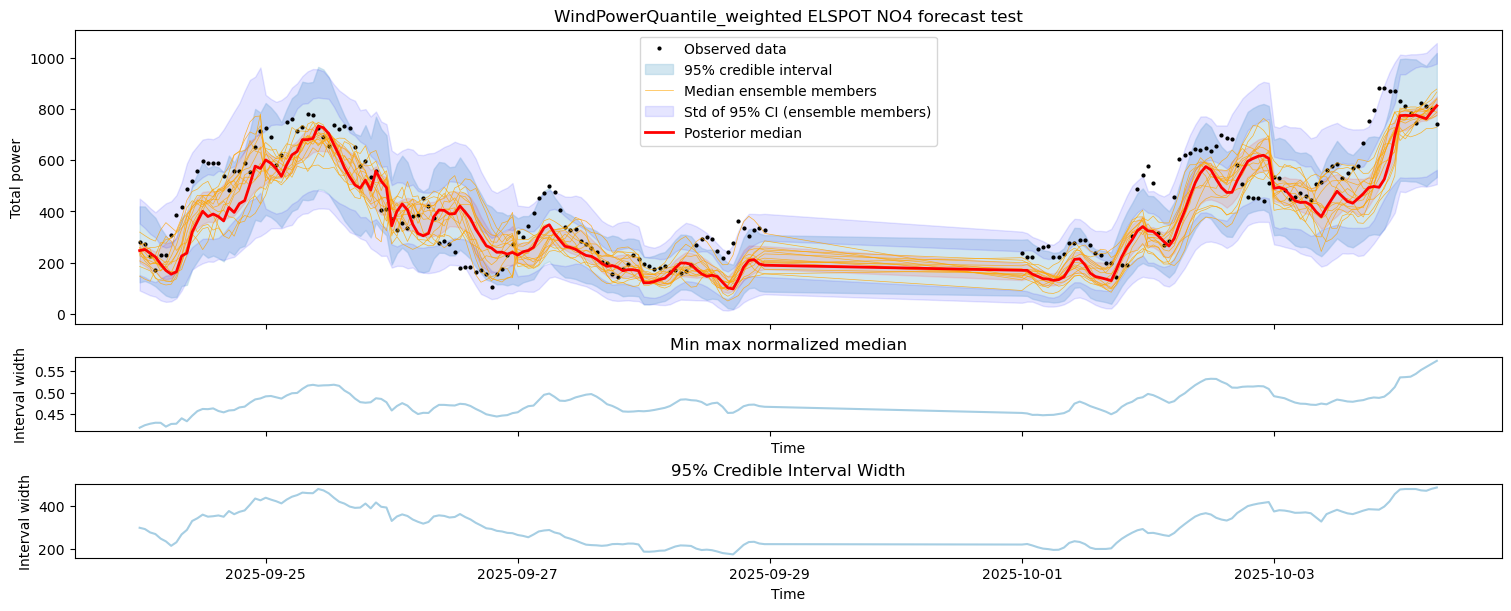

In [16]:
fix, axes = plot_qr_hdi_prediction_ensemble(
    Y_true=eval_data["Y_eval_gen"],
    ensemble_results=df_out,
    plot_interval=[0, 200],
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} test",
    timestamps=eval_data["index"],
)

In [17]:
# OLD: Mean median and HDI, not median and HDI across all samples !!
#  plot_qr_hdi_prediction_ensemble_combined(
#     Y_true=eval_data["Y_eval_gen"],
#     conf_interval=[
#         np.stack(
#             [df_out["mean_hdi_lower"].values, df_out["mean_hdi_upper"].values], axis=-1
#         ),
#         np.stack([df_out["hdi_lower_0"].values, df_out["hdi_upper_0"].values], axis=-1),
#     ],
#     medians=[df_out["mean_median"].values, df_out["median_0"].values],
#     plot_interval=[0, 663],
#     title=f"{model_name_for_title}: Aggregated ensemble member prediction (test set, {model_cfg.data.bid_zone})",
#     timestamps=df_out.index,
# )
# plt.savefig(
#     f"../plots/ensemble_{data_cfg.dataset}_{model_name_for_title}_{model_cfg.data.bid_zone}_test.pdf"
# )

In [18]:
if model_cfg.backend == "numpyro":
    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], eval_data)

    plot_bnn_gamma_combined(checkpoint, model, eval_data, data_cfg, [0, 663], "eval")
    plt.savefig(
        f"../plots/ensemble_{data_cfg.dataset}_{model_name_for_title}_{model_cfg.data.bid_zone}_test.pdf"
    )

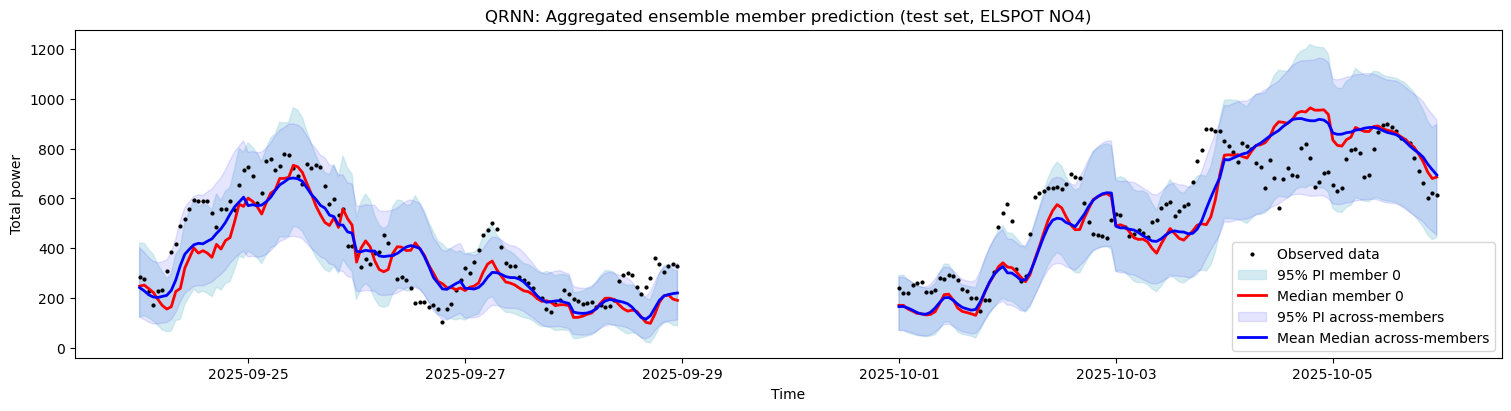

In [19]:
if model_cfg.backend == "torch":
    plot_qr_prediction_ensemble(
        Y_true=eval_data["Y_eval_gen"],
        Y_pred=preds_list,
        plot_interval=[0, 1080],
        title=f"{model_name_for_title}: Aggregated ensemble member prediction (test set, {model_cfg.data.bid_zone})",
        timestamps=eval_data["index"],
    )
    plt.savefig(
        f"../plots/ensemble_{data_cfg.dataset}_{model_name_for_title}_{model_cfg.data.bid_zone}_test.pdf"
    )

In [20]:
# # First, load nowcast data (or load existing scaler params)
# nowcast_data = load_and_preprocess_data(bid_zone="ELSPOT NO1")

In [21]:
# # Now load forecast data using the SAME scaler parameters

# forecast_data = load_and_preprocess_forecast_data(
#     scaler_params=None,
#     site_scaler_params=None,
#     bid_zone="ELSPOT NO1",
#     ensemble_member=0,  # Use member 0
#     data_path="../data",
# )

In [22]:
# # Plot cf vs gen model for QR
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-04_12-21-40_now_gen_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"QR Power Generation Prediction in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"QR Capacity Factor Prediction in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()

In [23]:
# # Plot cf vs gen model for BNN
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# file_name = "model_mw_gamma_2025-11-21_10-30-46_gen_ELSPOT_NO1"
# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"BNN Power Generation Prediction (Gamma) in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# file_name = "model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"BNN Capacity Factor Prediction (Beta) in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()